# 01 · Exploratory Data Analysis — NASA C-MAPSS FD001

**Goal of this notebook:** understand the data well enough to make three decisions with evidence:
1. how RUL labels are built (and why they are clipped at 125),
2. which of the 24 raw columns carry information (→ `config.DROP_COLS`),
3. what the test set really looks like (→ how models must be evaluated).

All logic lives in `src/` (`data_loader.py`, `eda.py`); this notebook only calls it and draws.
Figures are saved to `results/` for the README. Run from the repo root with the project venv as kernel.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd() if (pathlib.Path.cwd() / "src").exists() else pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import config
from src.data_loader import load_cmapss, load_rul_truth, compute_rul
from src.eda import screen_columns, suggest_drop_cols, lifetimes, align_to_failure
from src.plotting import (apply_style, save_fig, BLUE, ORANGE, AQUA, CATEGORICAL, MUTED,
                          TEXT_SECONDARY, DIVERGING)
apply_style()
pd.set_option("display.precision", 3)

## 1 · Load the data
Files are whitespace-separated with trailing spaces, so the loader uses `sep=r"\s+"`. It also *validates*
the structure (26 columns, no NaN, cycles 1, 2, 3 … with no gaps inside every engine), because the
rolling-window features later silently break if that is not true.

In [2]:
train = compute_rul(load_cmapss("FD001", "train"))
test = load_cmapss("FD001", "test")
truth = load_rul_truth("FD001")
print("train", train.shape, "| engines", train.unit_id.nunique())
print("test ", test.shape, "| engines", test.unit_id.nunique(), "| RUL truth values", len(truth))
train.head()

train (20631, 27) | engines 100
test  (13096, 26) | engines 100 | RUL truth values 100


,unit_id,cycle,op1,op2,op3,s1,s2,s3,s4,s5,...,s13,s14,s15,s16,s17,s18,s19,s20,s21,rul
0,1,1,-7.000e-04,-4.000e-04,100.0,518.67,641.82,1589.70,1400.60,14.62,...,2388.02,8138.62,8.419,0.03,392,2388,100.0,39.06,23.419,191
1,1,2,1.900e-03,-3.000e-04,100.0,518.67,642.15,1591.82,1403.14,14.62,...,2388.07,8131.49,8.432,0.03,392,2388,100.0,39.00,23.424,190
2,1,3,-4.300e-03,3.000e-04,100.0,518.67,642.35,1587.99,1404.20,14.62,...,2388.03,8133.23,8.418,0.03,390,2388,100.0,38.95,23.344,189
3,1,4,7.000e-04,0.000e+00,100.0,518.67,642.35,1582.79,1401.87,14.62,...,2388.08,8133.83,8.368,0.03,392,2388,100.0,38.88,23.374,188
4,1,5,-1.900e-03,-2.000e-04,100.0,518.67,642.37,1582.85,1406.22,14.62,...,2388.04,8133.80,8.429,0.03,393,2388,100.0,38.90,23.404,187


## 2 · RUL labels: how long does an engine live?
> **How to read this figure (histogram):** the x-axis is how many cycles an engine lasted; each bar's height is how many
> engines lasted that long. Wide spread = engines differ a lot. Dashed line = average.

Training engines run **until failure**, so each row's label is `RUL = last cycle − current cycle`
(0 at the failure cycle). Lifetimes vary a lot between engines — a model cannot just learn "fail at cycle 200".

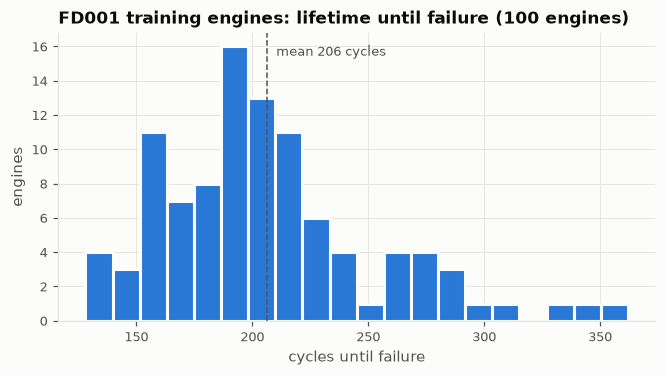

count    100.000
mean     206.310
std       46.343
min      128.000
25%      177.000
50%      199.000
75%      229.250
max      362.000
Name: lifetime, dtype: float64

In [3]:
life = lifetimes(train)
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.hist(life, bins=20, color=BLUE, edgecolor="#fcfcfb", linewidth=2)
ax.axvline(life.mean(), color=TEXT_SECONDARY, lw=1, ls="--")
ax.text(life.mean() + 4, ax.get_ylim()[1] * 0.92, f"mean {life.mean():.0f} cycles", color=TEXT_SECONDARY, fontsize=8.5)
ax.set(title="FD001 training engines: lifetime until failure (100 engines)", xlabel="cycles until failure", ylabel="engines")
save_fig(fig, "eda_lifetimes"); plt.show()
life.describe()

## 3 · Why clip RUL at 125?
> **How to read this figure:** one engine's life from left (new) to right (failed). Blue = the true cycles remaining,
> falling to 0. Orange = the label we actually train on: flat at 125 while healthy, then identical to blue.

Early in life an engine is healthy and its sensors are flat — there is **no signal** that distinguishes
"300 cycles left" from "200 cycles left". Asking a model to learn that difference teaches it noise.
The standard fix (used by essentially every C-MAPSS paper) is a *piecewise-linear* target:
RUL is capped at 125, so the target is flat while healthy and declines linearly once degradation starts.

**Project convention (docs/DECISIONS.md P3):** training/validation *labels* are clipped; the official test
truth (`RUL_FD001.txt`) is used **as given**.

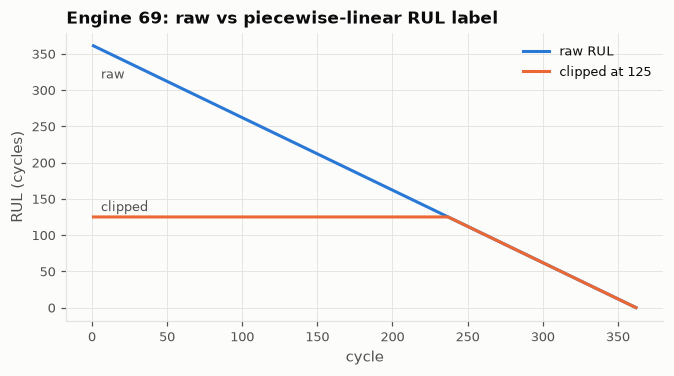

share of training rows affected by clipping: 38.9%


In [4]:
eng = life.idxmax()                       # longest-lived engine shows the effect best
e = train[train.unit_id == eng]
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(e.cycle, e.rul, color=BLUE, label="raw RUL")
ax.plot(e.cycle, e.rul.clip(upper=config.MAX_RUL), color=ORANGE, label=f"clipped at {config.MAX_RUL}")
ax.text(e.cycle.iloc[5], e.rul.iloc[5] - 40, "raw", color=TEXT_SECONDARY, fontsize=8.5)
ax.text(e.cycle.iloc[5], config.MAX_RUL + 8, "clipped", color=TEXT_SECONDARY, fontsize=8.5)
ax.set(title=f"Engine {eng}: raw vs piecewise-linear RUL label", xlabel="cycle", ylabel="RUL (cycles)")
ax.legend(loc="upper right")
save_fig(fig, "eda_rul_clipping"); plt.show()
print(f"share of training rows affected by clipping: {(train.rul > config.MAX_RUL).mean():.1%}")

## 4 · Which columns carry information?
> **How to read the bar chart below:** one bar per column; longer = the column changes more steadily as an engine ages
> (0 = no relation to age, 1 = perfectly steady). Grey bars are dropped; the gap between blue and grey is what makes
> the decision clear-cut.

For each of the 24 raw columns (3 operating settings + 21 sensors), `src/eda.screen_columns` computes:
- **n_unique** — 1 means the column is perfectly constant;
- **spearman_rul** — rank correlation with RUL, all engines pooled together;
- **within_engine_trend** — mean |correlation with cycle| computed *inside each engine*.

Why the last one: engines start at different baseline levels (manufacturing variation). Pooling engines can hide
a clear per-engine trend. **Drop rule** (`suggest_drop_cols`): ≤ 2 distinct values **or** within-engine trend < 0.2.

In [5]:
screen = screen_columns(train)
drop = suggest_drop_cols(screen)
print("suggested drop:", drop)
print("matches config.DROP_COLS:", sorted(drop) == sorted(config.DROP_COLS))
screen.sort_values("within_engine_trend", ascending=False)

suggested drop: ['op1', 'op2', 'op3', 's1', 's5', 's6', 's10', 's16', 's18', 's19']
matches config.DROP_COLS: True


,n_unique,std,spearman_rul,within_engine_trend
column,,,,
s11,159,2.671e-01,-0.718,0.810
s12,427,7.376e-01,0.693,0.784
s4,4051,9.001e+00,-0.702,0.774
s7,513,8.851e-01,0.679,0.752
s15,1918,3.751e-02,-0.666,0.711
s20,120,1.807e-01,0.653,0.703
s14,6078,1.908e+01,-0.202,0.703
s21,4745,1.083e-01,0.657,0.702
s13,56,7.192e-02,-0.573,0.680


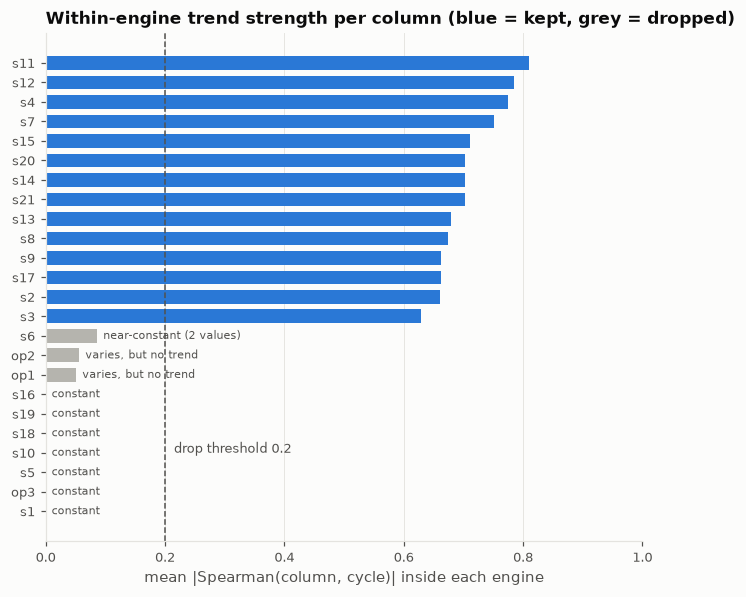

In [6]:
s = screen.sort_values("within_engine_trend")
colors = [MUTED if c in drop else BLUE for c in s.index]
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(s.index, s.within_engine_trend, color=colors, height=0.7)
ax.axvline(0.2, color=TEXT_SECONDARY, lw=1, ls="--")
ax.text(0.215, 3, "drop threshold 0.2", color=TEXT_SECONDARY, fontsize=8.5)
for i, (c, v) in enumerate(s.within_engine_trend.items()):
    if c in drop:
        why = "constant" if s.n_unique[c] == 1 else "near-constant (2 values)" if s.n_unique[c] == 2 else "varies, but no trend"
        ax.text(v + 0.01, i, why, va="center", fontsize=7.5, color=TEXT_SECONDARY)
ax.set(title="Within-engine trend strength per column (blue = kept, grey = dropped)",
       xlabel="mean |Spearman(column, cycle)| inside each engine", xlim=(0, 1))
ax.grid(axis="y", visible=False)
save_fig(fig, "eda_column_screening"); plt.show()

## 5 · What degradation looks like
> **How to read this figure:** each small panel is one sensor; each colour is one engine. The x-axis counts cycles
> *before failure*, so every engine ends at 0 on the right. Look for the shape: flat or noisy on the left, then a
> bend up or down toward 0 — that bend is degradation. Lining engines up at a shared event (failure) is a standard
> trick that makes such a pattern visible.

The 14 kept sensors for five engines (shortest, 25th percentile, median, 75th percentile and longest lifetime),
plotted against **cycles before failure** so every engine ends at x = 0. Aligned this way, the shared degradation
pattern appears: flat while healthy, then a drift that accelerates toward failure — the reason RUL is predictable at all.

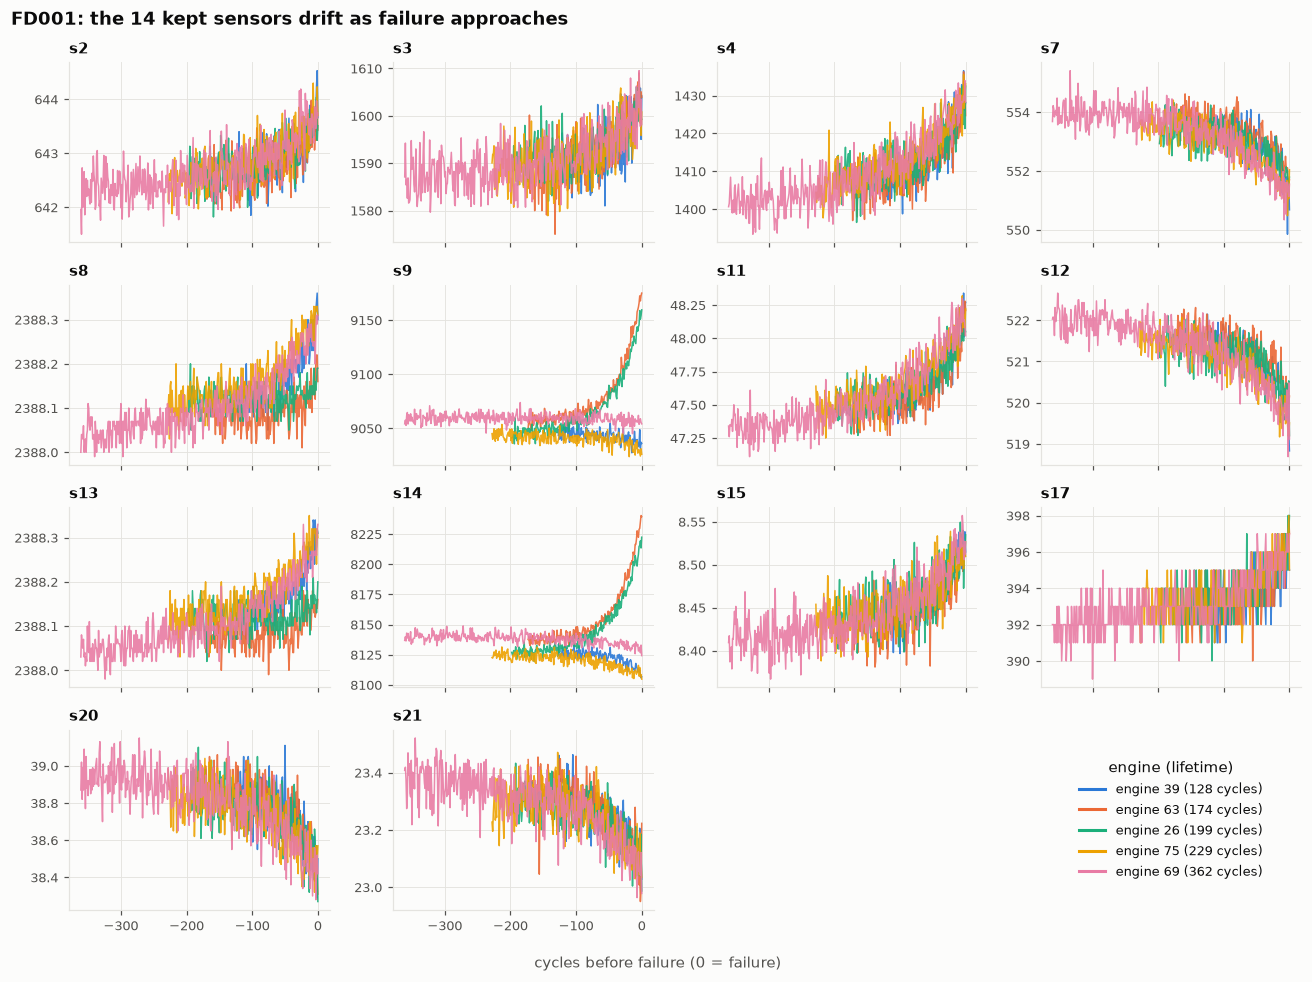

In [7]:
q = life.sort_values()
picks = [q.index[i] for i in (0, 24, 49, 74, 99)]
al = align_to_failure(train)
fig, axes = plt.subplots(4, 4, figsize=(12, 9), sharex=True)
for ax, sensor in zip(axes.flat, config.SENSORS):
    for k, u in enumerate(picks):
        d = al[al.unit_id == u]
        ax.plot(d.cycles_to_failure, d[sensor], color=CATEGORICAL[k], lw=1.0, alpha=0.9)
    ax.set_title(sensor, fontsize=9.5)
for ax in axes.flat[len(config.SENSORS):]:
    ax.axis("off")
handles = [plt.Line2D([], [], color=CATEGORICAL[k], lw=2) for k in range(5)]
axes.flat[-1].legend(handles, [f"engine {u} ({life[u]} cycles)" for u in picks], loc="center", title="engine (lifetime)")
fig.supxlabel("cycles before failure (0 = failure)", fontsize=9.5, color=TEXT_SECONDARY)
fig.suptitle("FD001: the 14 kept sensors drift as failure approaches", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
save_fig(fig, "eda_sensor_trends"); plt.show()

## 6 · s9 and s14: strong per-engine trends, but not one shared direction
> **How to read this figure:** left = every training row as one dot (all engines mixed): a cloud that fans out into
> an upper and a lower branch near RUL 0. Right = three engines drawn separately: two rise, one stays flat. The x-axis
> is reversed so failure (RUL 0) is on the right in both panels.

s9 and s14 have *weak* pooled correlation with RUL (|ρ| ≈ 0.2–0.3), so a correlation-only screen would drop them.
Inside each engine they *do* move steadily with age (within-engine trend ≈ 0.66–0.70) — but the figures show the
movement is **not the same for every engine**: in some engines s9/s14 shoot up near failure, in others they stay
flat or drift down. Pooling engines averages these opposite behaviours away.

**Decision:** keep both (they carry real per-engine information that sequence models can use, and the planned
14-sensor set is the benchmark convention). **Caveats recorded for later:** they are 96 % correlated with each
other (near-duplicates), and their engine-dependent direction makes them less reliable *on their own* — watch how
much weight SHAP gives them.

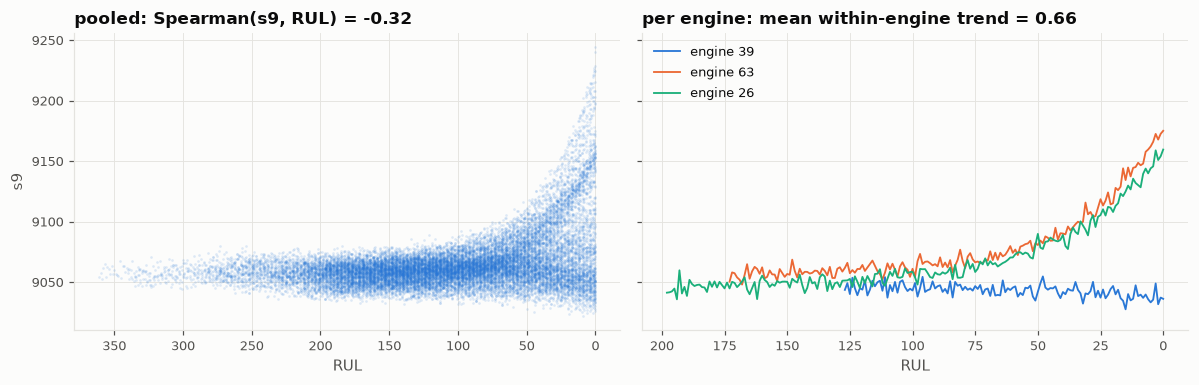

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
axes[0].scatter(train.rul, train.s9, s=3, color=BLUE, alpha=0.15, linewidths=0)
axes[0].set(title=f"pooled: Spearman(s9, RUL) = {screen.loc['s9', 'spearman_rul']:.2f}", xlabel="RUL", ylabel="s9")
for k, u in enumerate(picks[:3]):                  # <= 3 series for a point-dense view
    d = train[train.unit_id == u]
    axes[1].plot(d.rul, d.s9, color=CATEGORICAL[k], lw=1.2, label=f"engine {u}")
axes[1].set(title=f"per engine: mean within-engine trend = {screen.loc['s9', 'within_engine_trend']:.2f}", xlabel="RUL")
axes[1].invert_xaxis(); axes[0].invert_xaxis()
axes[1].legend(loc="upper left")
fig.tight_layout(); save_fig(fig, "eda_s9_hidden_trend"); plt.show()

## 7 · How the 14 sensors relate to each other and to RUL
> **How to read this figure (correlation heatmap):** every square answers *"when sensor A goes up, does sensor B go up
> too?"*. Dark blue = +1 (always together), dark orange = −1 (one up, the other down), pale = 0 (unrelated). The
> diagonal is always 1 (a sensor vs itself). The bottom row is each sensor vs RUL.

Pearson correlation on the training rows. Strongly correlated sensor pairs carry overlapping information —
fine for tree models and neural nets, but worth knowing when reading SHAP values later (credit can be split between twins).

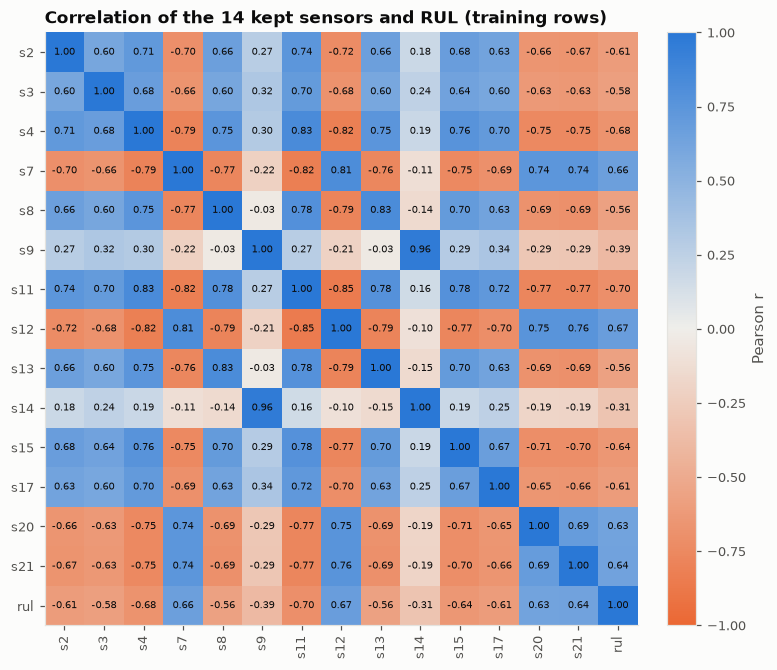

most correlated sensor pairs:
s9   s14    0.963
s11  s12    0.847
s4   s11    0.830
s8   s13    0.826
s7   s11    0.823
dtype: float64


In [9]:
corr = train[config.SENSORS + ["rul"]].corr()
fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(corr, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90); ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iat[i, j]:.2f}", ha="center", va="center", fontsize=6.5, color="#0b0b0b")
ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Pearson r")
ax.set_title("Correlation of the 14 kept sensors and RUL (training rows)")
save_fig(fig, "eda_correlation"); plt.show()
pairs = corr.drop(index="rul", columns="rul").where(np.triu(np.ones((14, 14), bool), 1)).stack()
print("most correlated sensor pairs:"); print(pairs.abs().sort_values(ascending=False).head(5).round(3))

## 8 · The test set is different — and that dictates evaluation
> **How to read this figure:** left — blue = how long training engines lived, orange = how much of each test engine
> we observed; orange sits further left because test engines were cut off before failure. Right — the true remaining
> cycles of each test engine; bars right of the dashed line are the engines with RUL > 125.

Test engines are **cut off before failure**. `RUL_FD001.txt` gives one number per engine: the cycles remaining
*after the last observed cycle*. So:
- a test engine has exactly **one** ground-truth value → evaluate on the **last window / last row** of each test engine;
- test RUL can never be computed from `max(cycle)` — these engines did not fail;
- the shortest test engine has 31 observed cycles ≥ the 30-cycle window → no padding needed for FD001.

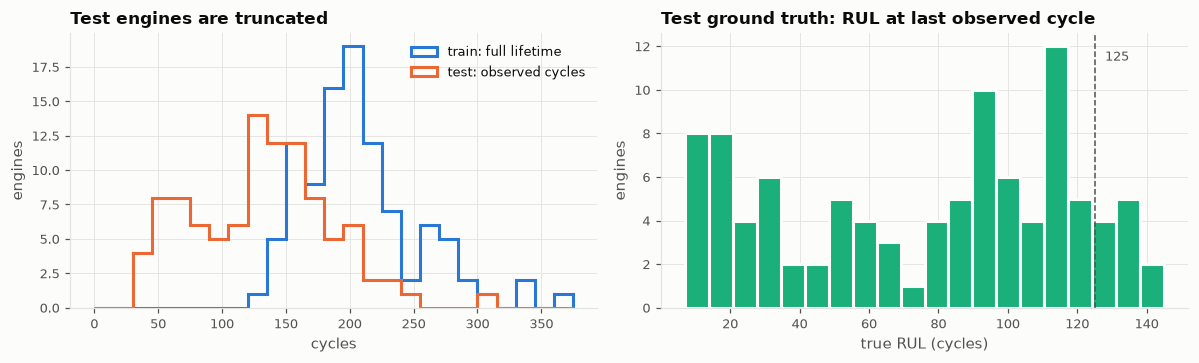

test observed cycles: min 31, median 134, max 303
test RUL truth: min 7, median 86, max 145; 11 of 100 engines have true RUL > 125


In [10]:
obs = test.groupby("unit_id").cycle.max()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
bins = np.arange(0, 380, 15)
axes[0].hist(life, bins=bins, histtype="step", lw=2, color=BLUE, label="train: full lifetime")
axes[0].hist(obs, bins=bins, histtype="step", lw=2, color=ORANGE, label="test: observed cycles")
axes[0].set(title="Test engines are truncated", xlabel="cycles", ylabel="engines"); axes[0].legend()
axes[1].hist(truth, bins=20, color=AQUA, edgecolor="#fcfcfb", linewidth=2)
axes[1].axvline(config.MAX_RUL, color=TEXT_SECONDARY, lw=1, ls="--")
axes[1].text(config.MAX_RUL + 3, axes[1].get_ylim()[1] * 0.9, "125", color=TEXT_SECONDARY, fontsize=8.5)
axes[1].set(title="Test ground truth: RUL at last observed cycle", xlabel="true RUL (cycles)", ylabel="engines")
fig.tight_layout(); save_fig(fig, "eda_test_set"); plt.show()
print(f"test observed cycles: min {obs.min()}, median {obs.median():.0f}, max {obs.max()}")
print(f"test RUL truth: min {truth.min()}, median {np.median(truth):.0f}, max {truth.max()}; "
      f"{(truth > config.MAX_RUL).sum()} of {len(truth)} engines have true RUL > {config.MAX_RUL}")

## Key findings (FD001)
*Numbers below are printed by the cells above; re-running the notebook reproduces them.*

1. **Data is clean and well-formed.** 20,631 training rows, 100 train / 100 test engines, no NaN, cycles contiguous in every engine.
2. **Lifetimes vary widely:** 128–362 cycles (mean 206). The model must read *condition*, not count cycles.
3. **RUL clipping at 125 affects 38.9 % of training rows** — the long healthy phase where sensors are flat and RUL is unlearnable.
4. **10 of 24 columns are dropped, by an explicit rule** (`src/eda.suggest_drop_cols`):
   7 perfectly constant (op3, s1, s5, s10, s16, s18, s19), 1 near-constant (s6, 2 values),
   2 varying-but-trendless (op1, op2 — noise, because FD001 has one operating condition).
   **The planned `config.DROP_COLS` is confirmed exactly**; a test (`tests/test_eda.py`) keeps it that way.
5. **The 14 kept sensors all degrade visibly toward failure** (trend 0.63–0.81), most of them consistently in one direction.
6. **s9/s14 are the exception:** strong per-engine trends whose *direction differs between engines*, and they are
   96 % correlated with each other. Kept, with that caveat noted for SHAP interpretation.
7. **Many sensors are strongly inter-correlated** (s11–s12 0.85, s4–s11 0.83, s8–s13 0.83) — one underlying degradation
   process seen by several sensors. Expect SHAP credit to be shared between correlated sensors.
8. **Test set:** engines are truncated (observed 31–303 cycles, median 134); ground truth RUL 7–145 (median 86).
   - Shortest test engine = 31 cycles ≥ 30-cycle window → no padding needed for FD001.
   - **11 of 100 test engines have true RUL > 125.** Models trained on clipped labels predict at most 125, so on those
     engines an error of up to 20 cycles is unavoidable when scoring against the *unclipped* truth (our convention, P3).
     Our RMSE will therefore be somewhat higher than papers that also clip the test truth — this is stated in the README.